In [169]:
import pya
from pya import *
import SiEPIC
from SiEPIC._globals import Python_Env
from SiEPIC.scripts import connect_cell, connect_pins_with_waveguide, zoom_out, export_layout
from SiEPIC.utils import create_cell2, get_layout_variables
from SiEPIC.utils.layout import new_layout, floorplan, coupler_array
from SiEPIC.extend import to_itype
from SiEPIC.verification import layout_check
import numpy as np
from SiEPIC.scripts import connect_pins_with_waveguide, connect_cell
import os
import sys



In [170]:

if Python_Env == 'Script':

    # Define the path to your local PDK
    path_to_pdk = r"D:\GitHub"
    # path_GitHub = r"C:\Users\gamem\OneDrive - UBC\Documents\GitHub"

    sys.path.insert(0, os.path.join(path_to_pdk, "SiEPICfab-EBeam-ZEP-PDK"))

    # Now try importing the PDK
    import SiEPICfab_EBeam_ZEP



In [171]:
tech_name = 'SiEPICfab_EBeam_ZEP'  # Can change this
gclib_name = 'SiEPICfab_EBeam_ZEP_Superconducting'
lib_name = 'SiEPICfab_EBeam_ZEP_Beta'

top_cell_name = 'regionL2'  # Change this to the name of the top cell from the floorplan

chip_name = 'SiEPICfab_ZEP_2603'  # Change this to the name of the .oas file from the folder gds_floorplan
chip_folder = 'SiEPICfab_ZEP_SNSPDPASSIVE_202504'


chip_file = os.path.join("gds_floorplan", f"{chip_name}.oas")  # Main chip file in floorplan
layout_file = os.path.join("designs", f"{top_cell_name}.oas")  # Name of the soon-to-be chip


In [172]:
"""
This script is used to extract a cell from a floorplan and save it as a GDS file.
Worry less about it, just run it and it will do the job.
"""

_, _ly = new_layout(tech_name, "test", GUI=True, overwrite = False)
_ly.read(chip_file)
_top_cell = _ly.cell(top_cell_name)
_top_cell.write(layout_file) #save the layout to a GDS file

In [173]:
"""
This script is used to open a GDS file and display it in KLayout.
Creates a new layout and reads the GDS file the above cell made.
"""


_, ly = new_layout(tech_name, "test", GUI=True, overwrite = False)
ly.read(layout_file)
# Access the top cell
top_cell = ly.cell(top_cell_name)

dbu = ly.dbu
wg_bend_radius = 20
              

top_cell.plot() # in the browser
top_cell.show() # in KLayout

Message from klive: {"version": "0.4.1", "klayout_version": "0.29.4", "type": "reload", "file": "C:\\Users\\jxs\\AppData\\Local\\Temp\\tmp1gw6cy1r\\regionL2.gds"}


In [174]:
top_cell.bbox().width()*dbu, top_cell.bbox().height()*dbu, top_cell.bbox().right, top_cell.bbox().top # just useful to confirm the size of the cell

(4205.908, 2850.0, 4205908, 2850000)

Message from klive: {"version": "0.4.1", "klayout_version": "0.29.4", "type": "reload", "file": "C:\\Users\\jxs\\AppData\\Local\\Temp\\tmp1gw6cy1r\\regionL2.gds"}


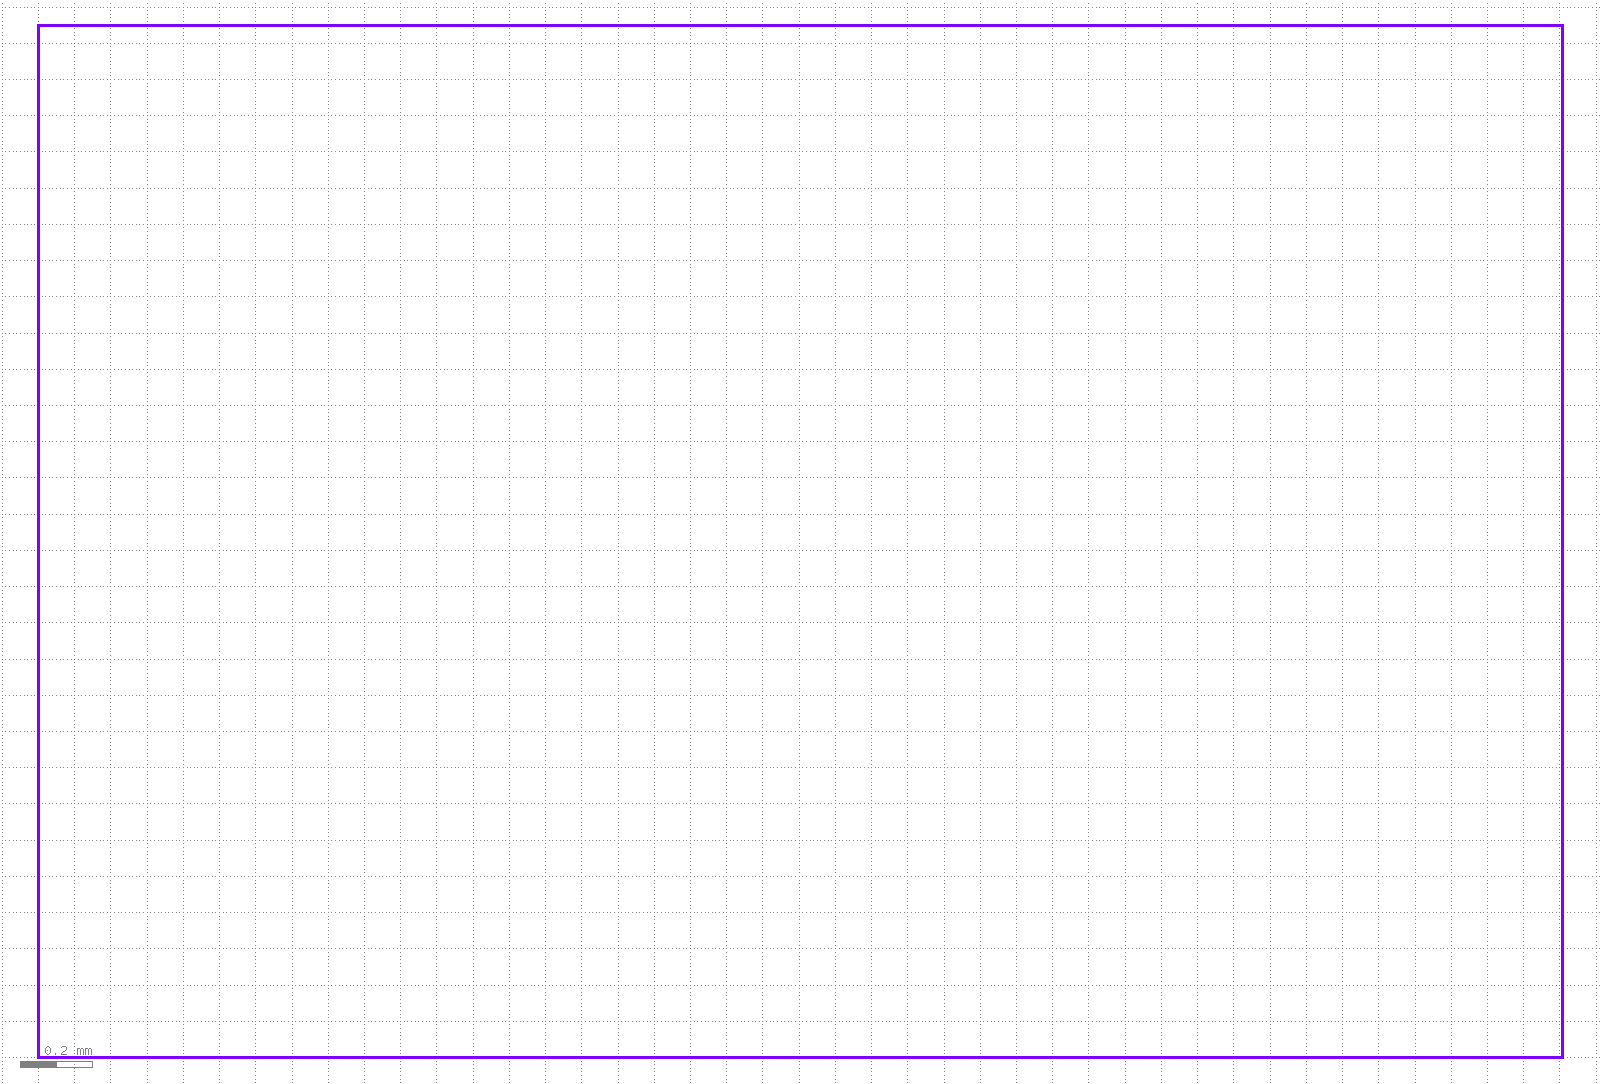

In [175]:
# Zoom out
# zoom_out(cell)
top_cell.show() # in KLayout GUI
top_cell.plot() # in the browser

In [176]:
# ============================================================
# Global/default GC settings
# Define once and reuse in later cells
# ============================================================
GC_SETTINGS = {
    "gc_cell_name": "SiEPICfab_1550TE",
    "gc_library": gclib_name,
    "gc_pitch": 127.0,   # microns
    "default_num_gc": 4,
    "label_location": 2,
}
WG_SETTINGS = {
    "wg_type": "Strip TE 1550 nm, w=500 nm (core-clad)",
}
device_prefix = "opt_in_TE_1550_device_JSong"

margin_x = 250

In [177]:
def gc_loopback(
    x_pos_GC=0,
    y_pos_GC=None,
    cellname="gc_loopback",
    device_label="opt_in_TE_1550_device_JSong_Loopback",
    xmax=None,
    num_gc=None,
    port_pairs= [(0, 1)],
    x_spacing=20.0,
    row_spacing=None,
    turtle_A=None,
):
    """
    Place a GC array and connect selected GC pairs with loopback waveguides.

    Parameters
    ----------
    x_pos_GC, y_pos_GC : float
        GC array anchor position in microns.

    cellname : str
        New cell name.

    device_label : str
        Label attached to the GC array.

    xmax : float
        Maximum x position before wrapping to next row.

    num_gc : int
        Number of GCs in the array.

    port_pairs : list of tuple[int, int]
        GC index pairs to connect.
        Examples:
            [(0, 1)]             -> connect GC0 and GC1
            [(0, 1), (2, 3)]     -> connect GC0-GC1 and GC2-GC3

    turtle_A : list or list of lists or None
        Routing path(s) for connect_pins_with_waveguide.
        - If a single list is given, use the same turtle for all pairs.
        - If a list of lists is given, each pair uses its own turtle.

    Returns
    -------
    next_x, next_y, xmax
    """

    global GC_SETTINGS, WG_SETTINGS, device_prefix, margin_x

    gc_cell_name   = GC_SETTINGS["gc_cell_name"]
    gc_library     = GC_SETTINGS["gc_library"]
    gc_pitch       = GC_SETTINGS["gc_pitch"]
    label_location = GC_SETTINGS["label_location"]

    if num_gc is None:
        num_gc = GC_SETTINGS["default_num_gc"]

    if y_pos_GC is None:
        y_pos_GC = top_cell.bbox().height() * dbu

    if xmax is None:
        xmax = top_cell.bbox().width() * dbu

    if row_spacing is None:
        row_spacing = (num_gc - 1) * gc_pitch + 2 * wg_bend_radius

    # if port_pairs is None:
    #     port_pairs = [(0, 1)]

    if turtle_A is None:
        turtle_A = []

    wg_type = WG_SETTINGS["wg_type"]
    gc_ports = ["opt1"] * num_gc

    if num_gc < 2:
        raise ValueError("num_gc must be at least 2")

    # validate port_pairs
    for pair in port_pairs:
        if len(pair) != 2:
            raise ValueError(f"Each entry in port_pairs must have 2 indices, got {pair}")
        i, j = pair
        if not (0 <= i < num_gc and 0 <= j < num_gc):
            raise ValueError(f"Invalid GC pair {pair} for num_gc={num_gc}")

    # normalize turtle_A
    # case 1: single turtle for all pairs, e.g. [50, -90, 127, 90, 50]
    # case 2: one turtle per pair, e.g. [[...], [...]]
    if len(port_pairs) == 1:
        turtle_list = [turtle_A]
    else:
        if isinstance(turtle_A, list) and len(turtle_A) > 0 and isinstance(turtle_A[0], list):
            if len(turtle_A) != len(port_pairs):
                raise ValueError("Number of turtle paths must match number of port pairs")
            turtle_list = turtle_A
        else:
            turtle_list = [turtle_A for _ in port_pairs]

    # -----------------------------
    # Create new cell
    # -----------------------------
    cell = ly.create_cell(cellname)
    top_cell.insert(CellInstArray(cell.cell_index(), Trans(Trans.R0, 0, 0)))

    # -----------------------------
    # Load GC cell
    # -----------------------------
    cell_gc = create_cell2(ly, gc_cell_name, gc_library)
    if cell_gc is None:
        raise ValueError(f"Could not load GC cell '{gc_cell_name}' from library '{gc_library}'")

    # -----------------------------
    # Auto place first device near corners (top-left, top-right, bottom-left, bottom-right)
    # -----------------------------
    top_boundary = top_cell.bbox().height() * dbu
    bottom_boundary = 0
    left_boundary = 0
    right_boundary = xmax
    
    # Determine which corner we're near
    near_left = x_pos_GC < 100#xmax * 0.25
    near_right = x_pos_GC > xmax-150# * 0.75
    near_top = y_pos_GC > top_boundary-100# * 0.75
    near_bottom = y_pos_GC == 0 #top_boundary * 0.25
    
    if y_pos_GC == top_boundary or near_top:
        # Top corners
        y_pos_GC -= (num_gc - 1) * gc_pitch + cell_gc.bbox().height() * dbu / 2
        if x_pos_GC == 0 or near_left:
            # Top-left
            x_pos_GC = cell_gc.bbox().width() * dbu
            # y_pos_GC -= (num_gc - 1) * gc_pitch + cell_gc.bbox().height() * dbu / 2
        elif near_right:
            # Top-right
            x_pos_GC = xmax - cell_gc.bbox().width() * dbu
            # y_pos_GC -= (num_gc - 1) * gc_pitch + cell_gc.bbox().height() * dbu / 2
    elif near_bottom:
        # Bottom corners
        y_pos_GC += (1 - 1) * gc_pitch + cell_gc.bbox().height() * dbu / 2
        if near_left:
            # Bottom-left
            x_pos_GC = cell_gc.bbox().width() * dbu
            # y_pos_GC += (num_gc - 1) * gc_pitch + cell_gc.bbox().height() * dbu / 2
        elif near_right:
            # Bottom-right
            x_pos_GC = xmax - cell_gc.bbox().width() * dbu
            # y_pos_GC += (num_gc - 1) * gc_pitch + cell_gc.bbox().height() * dbu / 2

    # -----------------------------
    # Place GC array
    # -----------------------------
    inst_GCs = coupler_array(
        cell,
        cell_name=gc_cell_name,
        cell_library=gc_library,
        x_offset=x_pos_GC / dbu,
        y_offset=y_pos_GC / dbu,
        label=device_label,
        label_location=label_location,
        count=num_gc,
    )

    # -----------------------------
    # Connect selected GC pairs
    # -----------------------------
    for (i, j), turtle in zip(port_pairs, turtle_list):
        connect_pins_with_waveguide(
            inst_GCs[i], gc_ports[i],
            inst_GCs[j], gc_ports[j],
            # turtle_A=turtle,
            waveguide_type=wg_type,
            r=wg_bend_radius
        )

    # -----------------------------
    # Suggested next placement
    # -----------------------------
    next_x = cell.bbox().right * dbu + x_spacing + cell_gc.bbox().width() * dbu
    next_y = y_pos_GC

    if next_x + cell.bbox().width() * dbu > xmax:
        next_x = cell_gc.bbox().width() * dbu
        next_y = cell.bbox().bottom * dbu - row_spacing - cell_gc.bbox().height() * dbu / 2

    return next_x, next_y, xmax


In [178]:
def ArbSplitter_Ladder(
    x_pos_GC=0,
    y_pos_GC=None,
    cellname="YB_H2T",
    device_label="opt_in_TE_1550_device_JSong_H2T",
    xmax=None,
    num_gc=3,
    num_layer=3,
    device_cell_name="y_d8_split9901",
    device_library=lib_name,
    device_params=None,
    gc_ports=None,
    wg_type=None,
    x_spacing=20.0,
    row_spacing=None,
    first_dev_dx=50.0,     # um: first splitter offset from GC
    chain_dx=30.0,         # um: spacing between splitters along propagation
    branch_dy=30.0,        # um: downward offset for branch road
    add_terminators=False,
):
    """
    Main road:
        GC[1] -> Y1.opt1
        Y1.opt2 -> Y2.opt1
        Y2.opt2 -> Y3.opt1
        ...
        last_main.opt2 -> GC[0]

    Branch road:
        Y1.opt3 -> B1.opt1
        B1.opt3 -> B2.opt1
        B2.opt3 -> B3.opt1
        ...

    Notes
    -----
    - num_gc must be at least 2
    - num_layer >= 1
    - Uses head-to-tail routing only:
        opt2 -> opt1  (main road)
        opt3 -> opt1  (branch road)
    """

    global GC_SETTINGS, WG_SETTINGS, device_prefix, margin_x

    if device_params is None:
        device_params = {}

    if num_gc < 2:
        raise ValueError("num_gc must be at least 2.")
    if num_layer < 1:
        raise ValueError("num_layer must be at least 1.")

    # --------------------------------------------------------
    # Global settings
    # --------------------------------------------------------
    gc_cell_name   = GC_SETTINGS["gc_cell_name"]
    gc_library     = GC_SETTINGS["gc_library"]
    gc_pitch       = GC_SETTINGS["gc_pitch"]
    label_location = GC_SETTINGS["label_location"]

    if gc_ports is None:
        gc_ports = ["opt1"] * num_gc
    elif len(gc_ports) != num_gc:
        raise ValueError("gc_ports length must equal num_gc")

    if wg_type is None:
        wg_type = WG_SETTINGS["wg_type"]

    if y_pos_GC is None:
        y_pos_GC = top_cell.bbox().height() * dbu

    if xmax is None:
        xmax = top_cell.bbox().width() * dbu

    if row_spacing is None:
        row_spacing = (num_gc - 1) * gc_pitch + 2 * wg_bend_radius

    # --------------------------------------------------------
    # Create new cell
    # --------------------------------------------------------
    cell = ly.create_cell(cellname)
    top_cell.insert(CellInstArray(cell.cell_index(), Trans(Trans.R0, 0, 0)))

    # --------------------------------------------------------
    # Load GC and device cells
    # --------------------------------------------------------
    cell_gc = create_cell2(ly, gc_cell_name, gc_library)
    if cell_gc is None:
        raise ValueError(f"Could not load GC cell '{gc_cell_name}' from library '{gc_library}'")

    if device_params:
        cell_device = ly.create_cell(
            device_cell_name,
            device_library,
            device_params
        )
    else:
        cell_device = create_cell2(ly, device_cell_name, device_library)

    if cell_device is None:
        raise ValueError(
            f"Could not create/load device cell: "
            f"name='{device_cell_name}', library='{device_library}', params={device_params}"
        )

    cell_termin = None
    if add_terminators:
        cell_termin = create_cell2(ly, "ebeam_terminator_te1550", device_library)

    # --------------------------------------------------------
    # Auto place first structure near top-left
    # --------------------------------------------------------
    if x_pos_GC == 0 and y_pos_GC == top_cell.bbox().height() * dbu:
        x_pos_GC = cell_gc.bbox().width() * dbu
        y_pos_GC -= (num_gc - 1) * gc_pitch + cell_gc.bbox().height() * dbu / 2

    # --------------------------------------------------------
    # Place GC array
    # --------------------------------------------------------
    inst_GCs = coupler_array(
        cell,
        cell_name=gc_cell_name,
        cell_library=gc_library,
        x_offset=x_pos_GC / dbu,
        y_offset=y_pos_GC / dbu,
        label=device_label,
        label_location=label_location,
        count=num_gc,
    )

    # ========================================================
    # 1) Build MAIN chain from GC[1] toward GC[0]
    # ========================================================
    branch_chainopt2 = []

    # First main splitter connected to GC[1]
    y1 = connect_cell(inst_GCs[1], gc_ports[1], cell_device, "opt1", translation=Trans.R0)
    y1.transform(Trans(int(first_dev_dx / dbu), 0))

    connect_pins_with_waveguide(
        inst_GCs[1], gc_ports[1],
        y1, "opt1",
        waveguide_type=wg_type,
        r=wg_bend_radius
    )

    branch_chainopt2.append(y1)

    # Remaining main splitters: prev.opt2 -> new.opt1
    for i in range(1, num_layer):
        prev = branch_chainopt2[-1]

        new_dev = connect_cell(prev, "opt2", cell_device, "opt1", translation=Trans.R0)
        new_dev.transform(Trans(int(chain_dx / dbu), int(branch_dy / dbu))) if i == 1 else 0

        connect_pins_with_waveguide(
            prev, "opt2",
            new_dev, "opt1",
            waveguide_type=wg_type,
            r=wg_bend_radius
        )

        branch_chainopt2.append(new_dev)
        t = connect_cell(new_dev, "opt3", cell_termin, "pin1", translation=Trans.R0)

    # Connect last main splitter to GC[0]
    connect_pins_with_waveguide(
        branch_chainopt2[-1], "opt2",
        inst_GCs[0], gc_ports[0],
        waveguide_type=wg_type,
        r=wg_bend_radius
    )

    # ========================================================
    # 2) Build BRANCH chain from Y1.opt3 using opt3 -> opt1
    # ========================================================
    branch_chainopt3 = [y1]

    # # First branch splitter comes from Y1.opt3
    # b1 = connect_cell(main_chain[0], "opt3", cell_device, "opt1", translation=Trans.R0)
    # b1.transform(Trans(int(chain_dx / dbu), int(-branch_dy / dbu)))

    # connect_pins_with_waveguide(
    #     main_chain[0], "opt3",
    #     b1, "opt1",
    #     waveguide_type=wg_type,
    #     r=wg_bend_radius
    # )

    # branch_chain.append(b1)
    

    # Remaining branch splitters: prev.opt3 -> new.opt1
    for i in range(1, num_layer):
        prev = branch_chainopt3[-1]

        new_dev = connect_cell(prev, "opt3", cell_device, "opt1", translation=Trans.R0)
        new_dev.transform(Trans(int(chain_dx / dbu), -int(branch_dy / dbu))) if i == 1 else 0
        

        connect_pins_with_waveguide(
            prev, "opt3",
            new_dev, "opt1",
            waveguide_type=wg_type,
            r=wg_bend_radius
        )

        branch_chainopt3.append(new_dev)
        t = connect_cell(new_dev, "opt2", cell_termin, "pin1", translation=Trans.R0)

    # Connect last main splitter to GC[0]
    connect_pins_with_waveguide(
        branch_chainopt3[-1], "opt3",
        inst_GCs[2], gc_ports[2],
        waveguide_type=wg_type,
        r=wg_bend_radius
    )
    # ========================================================
    # 3) Optional terminators on unused ports
    # ========================================================
    terminators = []

    # if add_terminators and cell_termin is not None and chain_dx != 0:
    #     # terminate unused opt3 ports on main road except the first one (used for branch road)
    #     for dev in main_chain[1:]:
    #         t = connect_cell(dev, "opt3", cell_termin, "opt1", translation=Trans.R0)
    #         terminators.append(t)

    #     # terminate unused opt2 ports on branch road
    #     for dev in branch_chain:
    #         t = connect_cell(dev, "opt2", cell_termin, "opt1", translation=Trans.R0)
    #         terminators.append(t)

    #     # terminate end of branch road if desired
    #     if len(branch_chain) > 0:
    #         t = connect_cell(branch_chain[-1], "opt3", cell_termin, "opt1", translation=Trans.R0)
    #         terminators.append(t)

    # --------------------------------------------------------
    # Suggested next placement
    # --------------------------------------------------------
    next_x = cell.bbox().right * dbu + x_spacing + cell_gc.bbox().width() * dbu
    next_y = y_pos_GC

    if next_x + cell.bbox().width() * dbu > xmax - margin_x:
        next_x = cell_gc.bbox().width() * dbu
        next_y = cell.bbox().bottom * dbu - row_spacing - cell_gc.bbox().height() * dbu / 2

    return next_x, next_y, xmax, branch_chainopt2, branch_chainopt3, terminators

In [179]:

# x = 0
# y = top_cell.bbox().height() * dbu
# xmax = top_cell.bbox().width() * dbu

# x, y, xmax, main_chain, branch_chain, terms = ArbSplitter_Ladder(
#     x_pos_GC=x,
#     y_pos_GC=y,
#     cellname="YB_H2T_01",
#     device_label="opt_in_TE_1550_JSong_YB7030_H2T_L3_ID1",
#     xmax=xmax,
#     num_gc=3,
#     num_layer=3,
#     device_cell_name="y_d8_split9901",
#     device_library=lib_name,
#     device_params=None,
#     gc_ports=None,
#     wg_type=None,
#     x_spacing=20.0,
#     row_spacing=None,
#     first_dev_dx=50.0,
#     chain_dx=wg_bend_radius*2,
#     branch_dy=wg_bend_radius*2,
#     add_terminators=True,
# )
# top_cell.show()
# top_cell.plot()

In [180]:
def SelfDefineAlignment(
    x_pos_GC=0,
    y_pos_GC=None,
    cellname_suffix="LT",
    device_label_area="_Default",
    xmax=None,
    num_loopback=2,
    port_pairs_list=None,
    x_spacing=20.0,
    row_spacing=None,
):
    """
    Generate multiple loopback structures with a given prefix.

    Parameters
    ----------
    x_pos_GC, y_pos_GC : float
        Starting position in microns.

    cellname_prefix : str
        Prefix for cell names (e.g., "GC_loopback").

    device_label_area : str
        Label area suffix (e.g., "_Ladd").

    xmax : float
        Maximum x position before wrapping to next row.

    num_loopback : int
        Number of loopback structures to generate.

    port_pairs_list : list of list of tuple or None
        List of port_pairs for each loopback.
        If None, defaults to [(0, 1), (2, 3)] for all.

    x_spacing, row_spacing : float
        Spacing parameters passed to gc_loopback.

    Returns
    -------
    next_x, next_y, xmax
    """

    global GC_SETTINGS, WG_SETTINGS, device_prefix, top_cell, dbu, wg_bend_radius

    if y_pos_GC is None:
        y_pos_GC = top_cell.bbox().height() * dbu

    if xmax is None:
        xmax = top_cell.bbox().width() * dbu

    if port_pairs_list is None:
        port_pairs_list = [[(0, 1), (2, 3)] for _ in range(num_loopback)]

    # Ensure port_pairs_list has the right length
    if len(port_pairs_list) < num_loopback:
        port_pairs_list.extend([[(0, 1), (2, 3)] for _ in range(num_loopback - len(port_pairs_list))])

    # Generate each loopback structure
    for i in range(num_loopback):
        # Create numbered cell name
        cellname = f"GCloopback{cellname_suffix}{i+1}"

        x_pos_GC, y_pos_GC, xmax = gc_loopback(
            x_pos_GC=x_pos_GC,
            y_pos_GC=y_pos_GC,
            cellname=cellname,
            device_label=device_prefix + device_label_area + "_" + cellname,
            xmax=None,
            num_gc=None,
            port_pairs=port_pairs_list[i],
            x_spacing=x_spacing,
            row_spacing=row_spacing,
            turtle_A=None,
        )

    return x_pos_GC, y_pos_GC, xmax


Starting position: x=0 um, y=2850.0 um, xmax=4205.908 um
Pins are already connected; returning
Pins are already connected; returning
Pins are already connected; returning
Pins are already connected; returning
Pins are already connected; returning
Pins are already connected; returning
Pins are already connected; returning
Pins are already connected; returning
Pins are already connected; returning
Pins are already connected; returning
Pins are already connected; returning
Pins are already connected; returning
Pins are already connected; returning
Pins are already connected; returning
Pins are already connected; returning
Pins are already connected; returning
Pins are already connected; returning
Pins are already connected; returning
Pins are already connected; returning
Pins are already connected; returning
Pins are already connected; returning
Pins are already connected; returning
Pins are already connected; returning
Pins are already connected; returning
Pins are already connected; ret

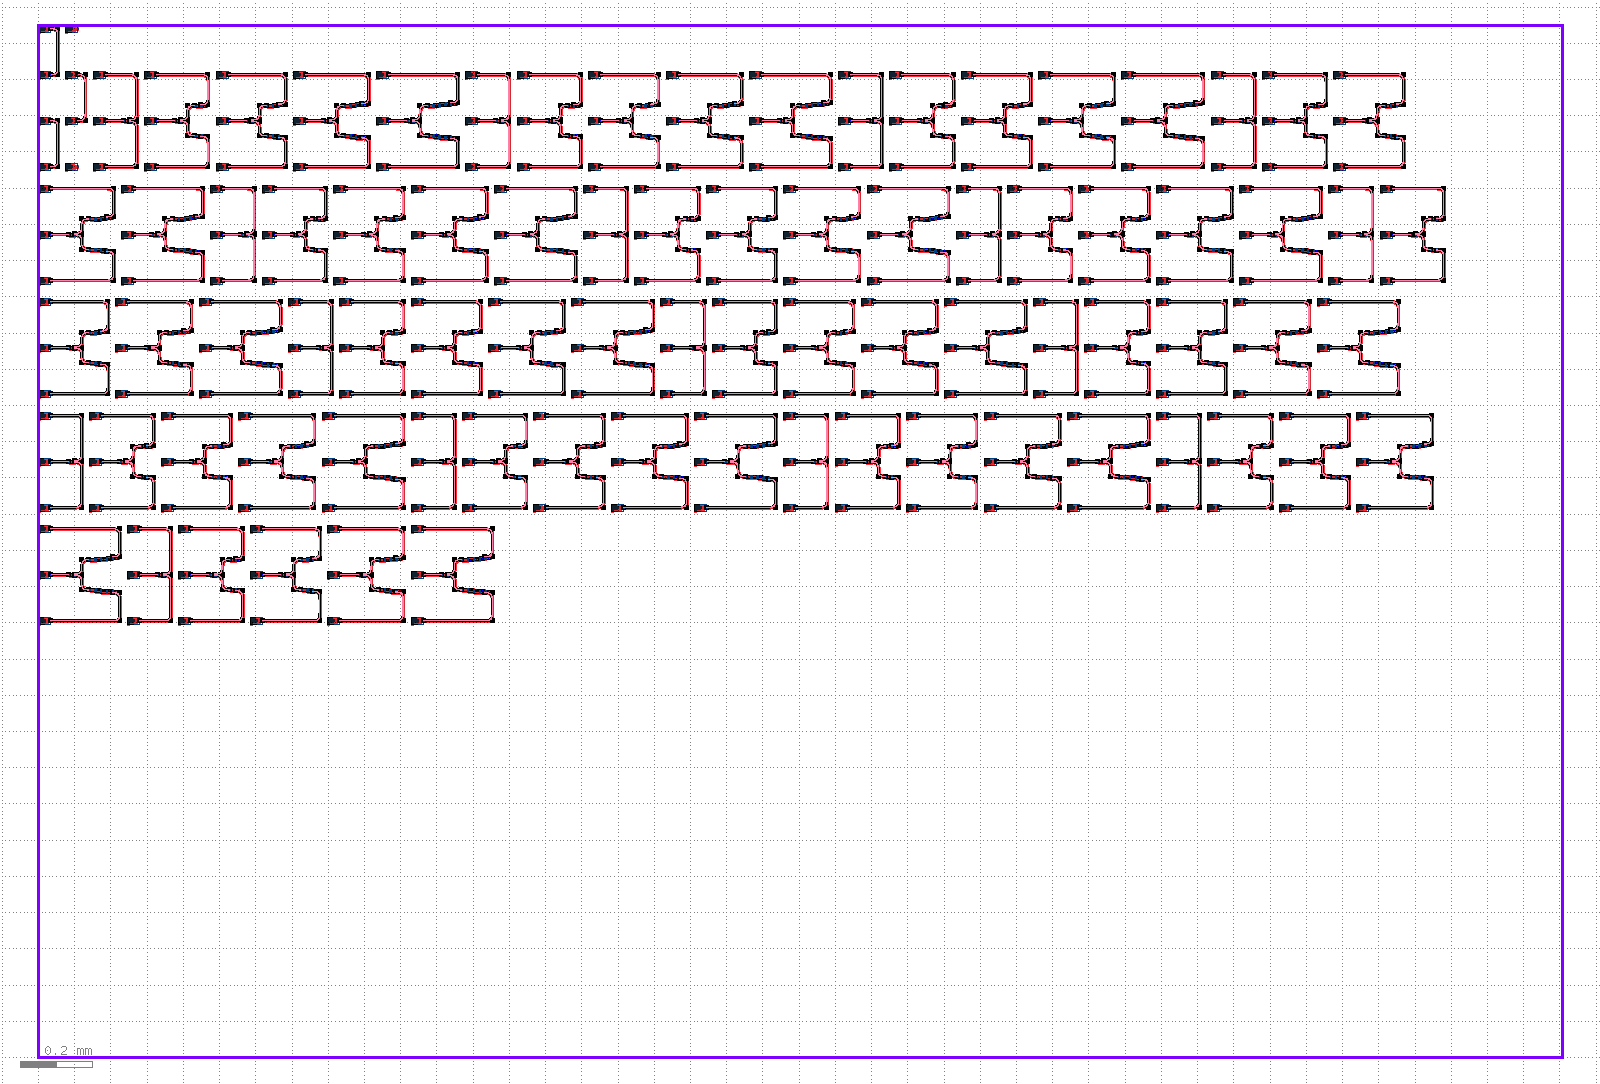

In [181]:
# Start near top-left of floorplan
device_label_area = "_Ladd"
x = 0
y = top_cell.bbox().height() * dbu
xmax = top_cell.bbox().width() * dbu
print(f"Starting position: x={x} um, y={y} um, xmax={xmax} um")
y_initial = y

# Generate loopback alignment structures
x, y, xmax = SelfDefineAlignment(
    x_pos_GC=x,
    y_pos_GC=y,
    cellname_suffix="LT",
    device_label_area=device_label_area,
    xmax=xmax,
    num_loopback=2,
    port_pairs_list=[[(0, 1), (2, 3)], [(1, 2)]],
    x_spacing=20.0,
    row_spacing=None,
)
 
# Device sequence to sweep
device_cell_name_sequence = [
    "y_d1_split5050",
    "y_d2_split6040",
    "y_d3_split7030",
    "y_d4_split8020",
    "y_d5_split9010",
    "y_d6_split9505",
    "y_d7_split9802",
    "y_d8_split9901",

    # "ebeam_ybranch_te1550",
]


N_repeat = 2
N_Ladder_sequence = [1, 2, 3, 4, 5]
r =1
for r in range(1, N_repeat + 1):
    for i, dev_name in enumerate(device_cell_name_sequence, start=1):
        for N in N_Ladder_sequence:
            cellname = f"Yspid{i}_Ladder{N}_rep{r}"
            label = device_prefix+device_label_area+f"_{dev_name}"

            x, y, xmax, branch_chainopt2, branch_chainopt3, terms = ArbSplitter_Ladder(
                x_pos_GC=x,
                y_pos_GC=y,
                cellname=cellname,
                device_label=label,
                xmax=xmax,
                num_gc=3,
                num_layer=N,
                device_cell_name="y_d8_split9901",
                device_library=lib_name,
                device_params=None,
                gc_ports=None,
                wg_type=None,
                x_spacing=20.0,
                row_spacing=None,
                first_dev_dx=50.0,
                chain_dx=wg_bend_radius*2,
                branch_dy=wg_bend_radius*2,
                add_terminators=True,
            )


top_cell.show()
top_cell.plot()


Message from klive: {"version": "0.4.1", "klayout_version": "0.29.4", "type": "reload", "file": "C:\\Users\\jxs\\AppData\\Local\\Temp\\tmp1gw6cy1r\\regionL2.gds"}


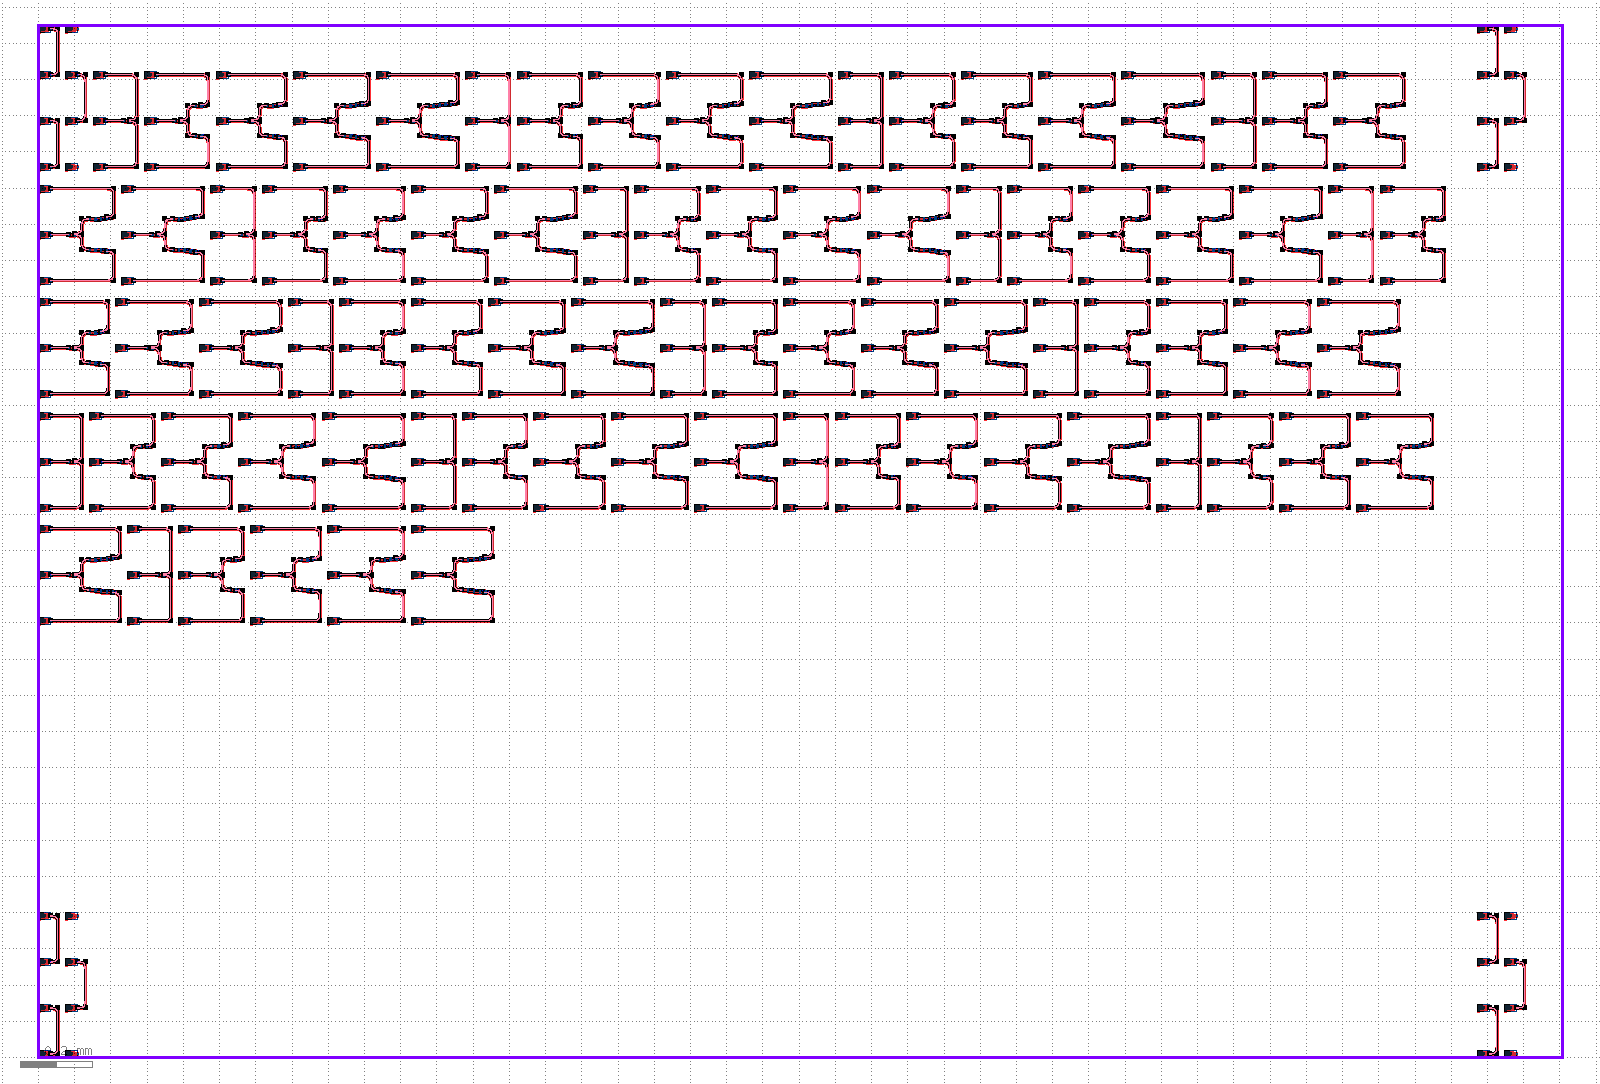

In [182]:

# Generate right-side loopback alignment structures at the same y as left-side
_, _, _ = SelfDefineAlignment(
    x_pos_GC=xmax-200,
    y_pos_GC=y_initial,
    cellname_suffix="RT",
    device_label_area=device_label_area,
    xmax=xmax,
    num_loopback=2,
    port_pairs_list=[[(0, 1), (2, 3)], [(1, 2)]],
    x_spacing=20.0,
    row_spacing=None,
)
# top_cell.show()
# top_cell.plot()


# Generate right-side loopback alignment structures at the same y as left-side
_, _, _ = SelfDefineAlignment(
    x_pos_GC=0,
    y_pos_GC=0,
    cellname_suffix="LB",
    device_label_area=device_label_area,
    xmax=xmax,
    num_loopback=2,
    port_pairs_list=[[(0, 1), (2, 3)], [(1, 2)]],
    x_spacing=20.0,
    row_spacing=None,
)

_, _, _ = SelfDefineAlignment(
    x_pos_GC=xmax-200,
    y_pos_GC=0,
    cellname_suffix="RB",
    device_label_area=device_label_area,
    xmax=xmax,
    num_loopback=2,
    port_pairs_list=[[(0, 1), (2, 3)], [(1, 2)]],
    x_spacing=20.0,
    row_spacing=None,
)


top_cell.show()
top_cell.plot()


In [183]:
from  SiEPICfab_ZEP_export import export_for_fabrication


gds_in = os.path.join("gds_in\\", f"{top_cell_name}")


export_for_fabrication(ly, top_cell, gds_in, flatten=True)

 - Warning: You may only have one top cell in your hierarchy. Clean up using SiEPIC > Layout > Delete Extra Top Cells.
 - Warning: Exporting top cell: regionL2
 - cell: regionL2
saving output OASIS: gds_in\regionL2_static.oas
Success. Layout exported successfully: 
gds_in\regionL2_static.oas
